# Human Baseline — Accuracy by Category

Direct vs inferential accuracy for Prolific human participants on the **occlusion** test.
All results use Combined scoring (correct if either GPT-5.4 or Claude Opus 4.6 judge says correct).

In [ ]:
# Run from the repo root so the root-relative data paths below resolve
import os
from pathlib import Path
os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sec3_occludebench").is_dir()))

In [17]:
import json
import os
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
from scipy import stats

JUDGED_PATH = 'data/eval_results_human/human_prolific_judged_results.json'
JUDGE_GPT    = 'gpt-5.4'
JUDGE_CLAUDE = 'claude-opus-4-6'
JUDGE_MODELS = [JUDGE_GPT, JUDGE_CLAUDE]

with open(JUDGED_PATH) as f:
    data = json.load(f)

print(f'Total entries: {len(data)}')
n_phys    = sum(1 for r in data if r.get('is_physical') is True)
n_nonphys = sum(1 for r in data if r.get('is_physical') is False)
print(f'Direct: {n_phys}  |  Inferential: {n_nonphys}')

import matplotlib as mpl

mpl.rcParams.update({
    'font.family':       'Arial',
    'font.size':         17,
    'axes.titlesize':    18,
    'axes.labelsize':    17,
    'xtick.labelsize':   17,
    'ytick.labelsize':   17,
    'legend.fontsize':   17,
    'axes.titleweight':  'normal',
    'axes.grid':         False,
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'figure.dpi':        150,
})

FIG_DIR = 'data/figures'
os.makedirs(FIG_DIR, exist_ok=True)

def save(fig, name):
    fig.savefig(os.path.join(FIG_DIR, name + '.pdf'), bbox_inches='tight', format='pdf')

Total entries: 2239
Direct: 1125  |  Inferential: 1114


In [18]:
def wilson_ci(k, n, z=1.96):
    if n == 0:
        return (None, None)
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return (100 * (center - margin), 100 * (center + margin))


def compute_accuracy(data, judge_models):
    """Returns dict: overall/physical/non_physical -> (pct, n_correct, n_total, ci_lo, ci_hi)."""
    buckets = {'overall': [], 'physical': [], 'non_physical': []}
    for r in data:
        correct_dict = r.get('correct', {})
        if not isinstance(correct_dict, dict):
            continue
        scores = [correct_dict.get(jm) for jm in judge_models]
        if any(s is None for s in scores):
            continue
        verdict = any(scores)  # OR
        buckets['overall'].append(verdict)
        if r.get('is_physical') is True:
            buckets['physical'].append(verdict)
        elif r.get('is_physical') is False:
            buckets['non_physical'].append(verdict)

    result = {}
    for key, vals in buckets.items():
        if vals:
            k, n = sum(vals), len(vals)
            pct = 100 * k / n
            ci_lo, ci_hi = wilson_ci(k, n)
            result[key] = (pct, k, n, ci_lo, ci_hi)
        else:
            result[key] = (None, 0, 0, None, None)
    return result


acc = compute_accuracy(data, JUDGE_MODELS)
for cat, (pct, correct, total, ci_lo, ci_hi) in acc.items():
    print(f'{cat:15s}: {pct:.1f}%  95% CI [{ci_lo:.1f}%, {ci_hi:.1f}%]  ({correct}/{total})')


overall        : 65.9%  95% CI [63.9%, 67.9%]  (1476/2239)
physical       : 63.4%  95% CI [60.5%, 66.1%]  (713/1125)
non_physical   : 68.5%  95% CI [65.7%, 71.2%]  (763/1114)


---
## Summary Table

In [19]:
label_map = {'overall': 'Overall', 'physical': 'Direct', 'non_physical': 'Inferential'}
rows = {}
for cat in ('overall', 'physical', 'non_physical'):
    pct, correct, total, ci_lo, ci_hi = acc[cat]
    rows[label_map[cat]] = f'{pct:.1f}%  [{ci_lo:.1f}, {ci_hi:.1f}]  ({correct}/{total})'

display(pd.DataFrame([rows], index=['Combined (OR)']))

,Overall,Direct,Inferential
Combined (OR),"65.9% [63.9, 67.9] (1476/2239)","63.4% [60.5, 66.1] (713/1125)","68.5% [65.7, 71.2] (763/1114)"


---
## Human Accuracy — Overall, Direct, Inferential

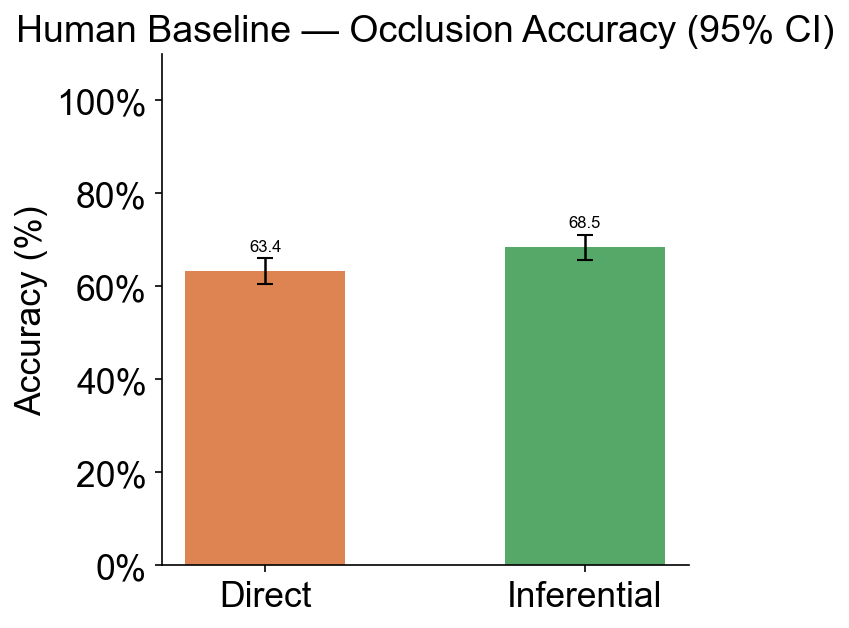

In [20]:
cat_keys   = ['physical', 'non_physical']
cat_labels = ['Direct', 'Inferential']
colors     = ['#DD8452', '#55A868']

x = np.arange(len(cat_keys))
width = 0.5

fig, ax = plt.subplots(figsize=(5, 4.5))

for i, (cat_key, cat_label, color) in enumerate(zip(cat_keys, cat_labels, colors)):
    pct, _, _, ci_lo, ci_hi = acc[cat_key]
    bar = ax.bar(i, pct, width, label=cat_label, color=color)
    ax.errorbar(i, pct,
                yerr=[[pct - ci_lo], [ci_hi - pct]],
                fmt='none', color='black', capsize=4, linewidth=1.2)
    ax.annotate(f'{pct:.1f}',
                xy=(i, pct),
                xytext=(0, 8), textcoords='offset points',
                ha='center', va='bottom', fontsize=8)

ax.set_title('Human Baseline — Occlusion Accuracy (95% CI)')
ax.set_xticks(x)
ax.set_xticklabels(cat_labels)
ax.set_ylim(0, 110)
ax.set_yticks([0, 20, 40, 60, 80, 100])
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_ylabel('Accuracy (%)')

plt.tight_layout()
save(fig, 'human_accuracy_bar')
plt.show()

---
## Per-Image Accuracy

In [21]:
from collections import defaultdict

image_buckets = defaultdict(lambda: {'verdicts': [], 'is_physical': None})

for r in data:
    correct_dict = r.get('correct', {})
    if not isinstance(correct_dict, dict):
        continue
    g = correct_dict.get(JUDGE_GPT)
    c = correct_dict.get(JUDGE_CLAUDE)
    if g is None or c is None:
        continue
    verdict = g or c
    img_id = r.get('image_id')
    image_buckets[img_id]['verdicts'].append(verdict)
    image_buckets[img_id]['is_physical'] = r.get('is_physical')

per_image = [
    {
        'image_id':   img_id,
        'accuracy':   100 * sum(v['verdicts']) / len(v['verdicts']),
        'is_physical': v['is_physical'],
    }
    for img_id, v in image_buckets.items()
    if v['verdicts'] and v['is_physical'] is not None
]

per_image_df     = pd.DataFrame(per_image)
per_image_sorted = per_image_df.sort_values('accuracy', ascending=False).reset_index(drop=True)
print(f'Images: {len(per_image_df)}  |  Physical: {per_image_df["is_physical"].sum()}  |  Non-physical: {(~per_image_df["is_physical"]).sum()}')


Images: 378  |  Physical: 197  |  Non-physical: 181


In [22]:
from scipy.stats import mannwhitneyu, ttest_ind
from statsmodels.stats.proportion import proportions_ztest

def get_response_counts(data, is_phys):
    correct, total = 0, 0
    for r in data:
        if r.get('is_physical') is not is_phys:
            continue
        cd = r.get('correct', {})
        g = cd.get(JUDGE_GPT)
        c = cd.get(JUDGE_CLAUDE)
        if g is None or c is None:
            continue
        total += 1
        if g or c:
            correct += 1
    return correct, total

phys_correct,    phys_total    = get_response_counts(data, True)
nonphys_correct, nonphys_total = get_response_counts(data, False)

z_stat, p_two_prop = proportions_ztest(
    [phys_correct, nonphys_correct],
    [phys_total,   nonphys_total]
)
print('Response-level z-test (direct vs inferential):')
print(f'  Direct:      {phys_correct}/{phys_total}  ({100*phys_correct/phys_total:.1f}%)')
print(f'  Inferential: {nonphys_correct}/{nonphys_total}  ({100*nonphys_correct/nonphys_total:.1f}%)')
print(f'  z = {z_stat:.3f},  p = {p_two_prop:.4f}')

phys_acc    = per_image_df.loc[per_image_df['is_physical'] == True,  'accuracy']
nonphys_acc = per_image_df.loc[per_image_df['is_physical'] == False, 'accuracy']
u_stat, p_mw = mannwhitneyu(phys_acc, nonphys_acc, alternative='two-sided')
t_stat, p_tt = ttest_ind(phys_acc, nonphys_acc, equal_var=False)

print(f'\nPer-image level:')
print(f'  Direct mean:      {phys_acc.mean():.1f}%  (n={len(phys_acc)} images)')
print(f'  Inferential mean: {nonphys_acc.mean():.1f}%  (n={len(nonphys_acc)} images)')
print(f'  Mann-Whitney U:  U = {u_stat:.1f},  p = {p_mw:.4f}')
print(f'  Welch t-test:    t = {t_stat:.3f},  p = {p_tt:.4f}')

Response-level z-test (direct vs inferential):
  Direct:      713/1125  (63.4%)
  Inferential: 763/1114  (68.5%)
  z = -2.553,  p = 0.0107

Per-image level:
  Direct mean:      63.0%  (n=197 images)
  Inferential mean: 68.0%  (n=181 images)
  Mann-Whitney U:  U = 15993.5,  p = 0.0811
  Welch t-test:    t = -1.589,  p = 0.1130


---
## Per-Image Accuracy Distribution

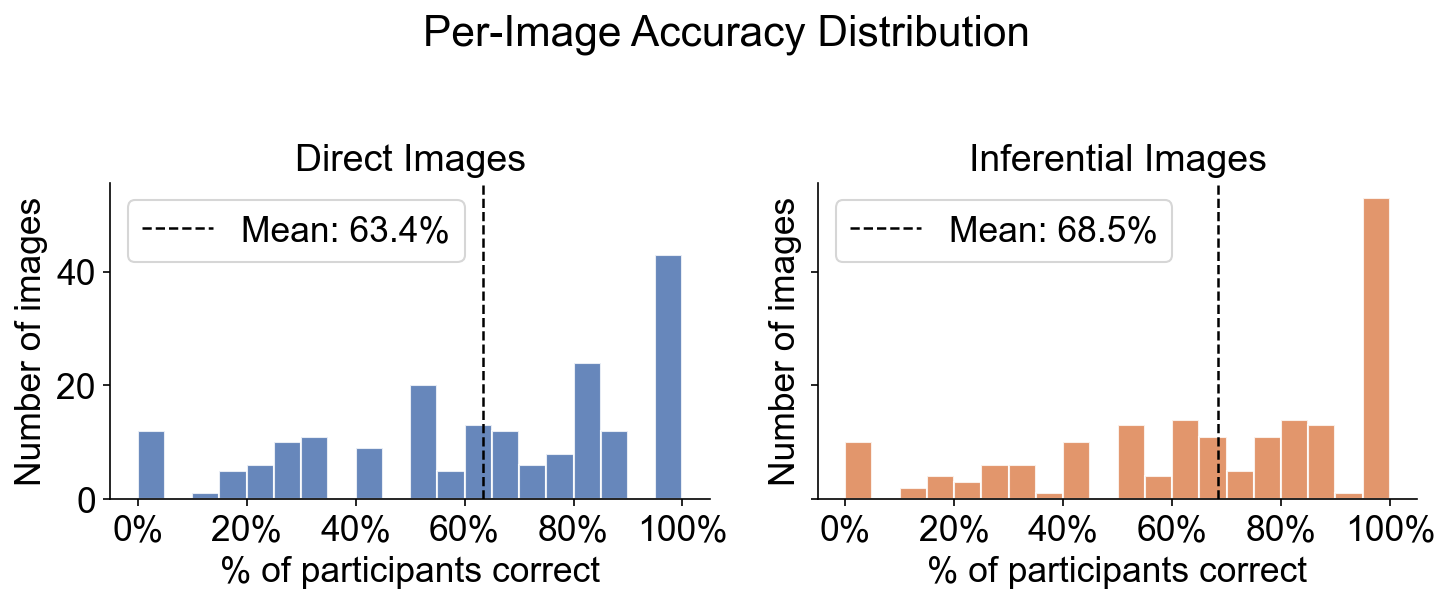

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

means = {'Direct': 63.4, 'Inferential': 68.5}

for ax, is_phys, label, color in zip(
    axes, [True, False], ['Direct', 'Inferential'], ['#4C72B0', '#DD8452']
):
    subset = per_image_df[per_image_df['is_physical'] == is_phys]['accuracy']
    mean_val = means[label]
    ax.hist(subset, bins=20, range=(0, 100), color=color, edgecolor='white', alpha=0.85)
    ax.axvline(mean_val, color='black', linestyle='--', linewidth=1.2,
               label=f'Mean: {mean_val:.1f}%')
    ax.set_title(f'{label} Images')
    ax.set_xlabel('% of participants correct')
    ax.set_ylabel('Number of images')
    ax.set_xticks([0, 20, 40, 60, 80, 100])
    ax.xaxis.set_major_formatter(mtick.PercentFormatter())
    ax.legend()

fig.suptitle('Per-Image Accuracy Distribution', y=1.02)
plt.tight_layout()
save(fig, 'human_per_image_dist')
plt.show()

---
## Per-Image Accuracy — Sorted

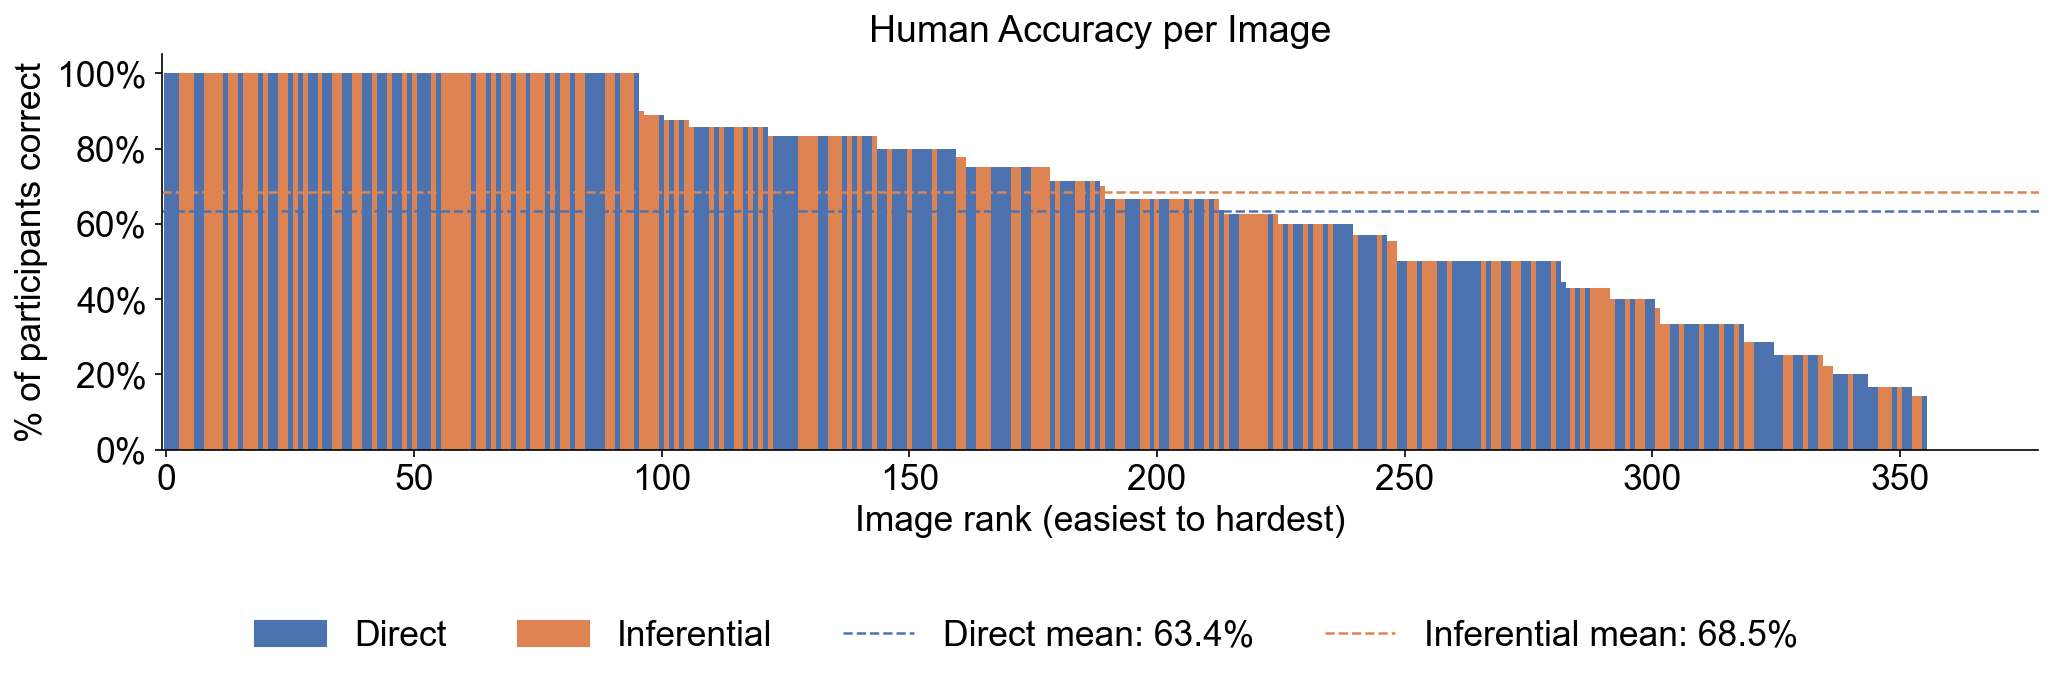

In [24]:
phys_acc_vals    = per_image_sorted.loc[per_image_sorted['is_physical'] == True,  'accuracy']
nonphys_acc_vals = per_image_sorted.loc[per_image_sorted['is_physical'] == False, 'accuracy']

DIRECT_MEAN = 63.4
INF_MEAN    = 68.5

fig, ax_bar = plt.subplots(figsize=(14, 4))

colors_bar = ['#4C72B0' if p else '#DD8452' for p in per_image_sorted['is_physical']]
ax_bar.bar(range(len(per_image_sorted)), per_image_sorted['accuracy'],
           color=colors_bar, width=1.0, linewidth=0)
ax_bar.axhline(DIRECT_MEAN, color='#4C72B0', linestyle='--', linewidth=1.2,
               label=f'Direct mean: {DIRECT_MEAN:.1f}%')
ax_bar.axhline(INF_MEAN,    color='#DD8452', linestyle='--', linewidth=1.2,
               label=f'Inferential mean: {INF_MEAN:.1f}%')
ax_bar.set_xlabel('Image rank (easiest to hardest)')
ax_bar.set_ylabel('% of participants correct')
ax_bar.set_title('Human Accuracy per Image')
ax_bar.set_xlim(-1, len(per_image_sorted))
ax_bar.set_ylim(0, 105)
ax_bar.set_yticks([0, 20, 40, 60, 80, 100])
ax_bar.yaxis.set_major_formatter(mtick.PercentFormatter())

import matplotlib.patches as mpatches
import matplotlib.lines as mlines
bar_handles = [
    mpatches.Patch(color='#4C72B0', label='Direct'),
    mpatches.Patch(color='#DD8452', label='Inferential'),
    mlines.Line2D([], [], color='#4C72B0', linestyle='--', linewidth=1.2, label=f'Direct mean: {DIRECT_MEAN:.1f}%'),
    mlines.Line2D([], [], color='#DD8452', linestyle='--', linewidth=1.2, label=f'Inferential mean: {INF_MEAN:.1f}%'),
]
fig.legend(handles=bar_handles, loc='lower center', ncol=4, bbox_to_anchor=(0.5, -0.18),
           frameon=False, fontsize=17)

plt.tight_layout()
save(fig, 'human_per_image_sorted')
plt.show()